# Predicting Missed 6-Minute Attendance Targets — London Fire Brigade

**Module:** 6COSC017C-n Machine Learning and Data Analytics — Coursework 1
**Student ID:** 00018680

**Business question.** The London Fire Brigade (LFB) aims to get the first fire engine to an incident
within **6 minutes** of the 999 call. This notebook builds a model that estimates, *using only information
available when the call is received*, the probability that the first engine will arrive **late (> 360 s)**.
Planners can use the model and its explanations to see where and when the target is at risk
(station locations, cover moves, staffing).

**Data.** London Datastore (Greater London Authority), Open Government Licence v2:
* LFB Incident Records — one row per incident (Jan 2024 – Oct 2026 file used)
* LFB Mobilisation Records — one row per fire engine sent (2021–2024 and 2025-onwards files, filtered to 2024+)

The two tables are joined on `IncidentNumber`.

**Structure:** A. Load data · B. Exploratory Data Analysis · C. Data Preparation & Feature Engineering ·
D. Model Training · E. Model Evaluation · F. Save artefacts for the Streamlit app

In [1]:
# Core libraries
import json, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             roc_curve, precision_recall_curve, ConfusionMatrixDisplay)
from scipy.stats import loguniform, randint, uniform
from lightgbm import LGBMClassifier

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42          # fixed seed -> reproducible results
TARGET_SECONDS = 360       # LFB first-appliance attendance standard (6 minutes)

# Paths work whether the notebook is run from the repo root or from notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
INTERIM = ROOT / "data" / "interim"; INTERIM.mkdir(parents=True, exist_ok=True)
PROCESSED = ROOT / "data" / "processed"; PROCESSED.mkdir(parents=True, exist_ok=True)
MODELS = ROOT / "models"; MODELS.mkdir(exist_ok=True)
FIGS = ROOT / "reports" / "figures"; FIGS.mkdir(parents=True, exist_ok=True)

def savefig(name):
    # Save every figure so it can be reused in the written report
    plt.savefig(FIGS / f"{name}.png", dpi=150, bbox_inches="tight")

## A. Load data

Two sources are loaded:

1. **Incidents** (`LFB Incident data from 2024 onwards.xlsx`). The Excel file is slow to parse, so the first
   run caches it as Parquet in `data/interim/` (git-ignored).
2. **Mobilisations**, which are split across two CSV files (2021–2024 and 2025-onwards). They are concatenated
   and filtered to `CalYear >= 2024` so they cover the same period as the incidents.

Using 2024 onwards keeps the analysis current (post-pandemic traffic patterns, current station
configuration) and keeps the dataset a manageable size (~400k incidents).

In [2]:
t0 = time.time()
inc_cache = INTERIM / "incidents_2024on.parquet"
if inc_cache.exists():
    incidents = pd.read_parquet(inc_cache)
else:
    incidents = pd.read_excel(RAW / "incident_records" / "LFB Incident data from 2024 onwards.xlsx")
    incidents.to_parquet(inc_cache, index=False)

mob_cache = INTERIM / "mobilisations_2024on.parquet"
if mob_cache.exists():
    mobilisations = pd.read_parquet(mob_cache)
else:
    mob_files = ["LFB Mobilisation data from 2021 - 2024.csv", "LFB Mobilisation data from 2025.csv"]
    mobilisations = pd.concat(
        [pd.read_csv(RAW / "mobilisation_records" / f, low_memory=False) for f in mob_files],
        ignore_index=True)
    mobilisations = mobilisations[mobilisations["CalYear"] >= 2024].reset_index(drop=True)
    mobilisations.to_parquet(mob_cache, index=False)

print(f"Loaded in {time.time() - t0:.0f}s")
print("Incidents:    ", incidents.shape)
print("Mobilisations:", mobilisations.shape)

Loaded in 0s
Incidents:     (397903, 39)
Mobilisations: (595128, 24)


In [3]:
incidents.head(3).T

,0,1,2
IncidentNumber,000002-01012024,000003-01012024,000007-01012024
DateOfCall,2024-01-01 00:00:00,2024-01-01 00:00:00,2024-01-01 00:00:00
CalYear,2024,2024,2024
TimeOfCall,00:00:43,00:01:11,00:04:21
HourOfCall,0,0,0
IncidentGroup,Special Service,Special Service,False Alarm
StopCodeDescription,Special Service,Special Service,False alarm - Good intent
SpecialServiceType,Advice Only,No action (not false alarm),NaN
PropertyCategory,Dwelling,Dwelling,Outdoor
PropertyType,Unlicensed House in Multiple Occupation - Up t...,Purpose Built Flats/Maisonettes - 10 or more s...,Loose refuse


In [4]:
mobilisations.head(3).T

,0,1,2
IncidentNumber,000002-01012024,000002-01012024,000003-01012024
CalYear,2024,2024,2024
BoroughName,WALTHAM FOREST,WALTHAM FOREST,HACKNEY
WardName,CANN HALL,CANN HALL,HAGGERSTON
HourOfCall,0,0,0
ResourceMobilisationId,6550786,6550787,6550788
Resource_Code,F301,F211,F241
PerformanceReporting,1,2,1
DateAndTimeMobilised,01/01/2024 00:00:43,01/01/2024 00:00:43,01/01/2024 00:01:11
DateAndTimeMobile,01/01/2024 00:00:57,01/01/2024 00:01:33,01/01/2024 00:01:30


### Join check

`IncidentNumber` is the key shared by both tables. Before joining we check that the key is unique in the
incident table (one row per incident) and how many incidents have matching mobilisation records.

In [5]:
print("Duplicate IncidentNumber in incidents:", incidents["IncidentNumber"].duplicated().sum())
inc_ids, mob_ids = set(incidents["IncidentNumber"]), set(mobilisations["IncidentNumber"])
print(f"Incidents with >=1 mobilisation: {len(inc_ids & mob_ids) / len(inc_ids):.1%}")
print(f"Mobilisations matching an incident: {mobilisations['IncidentNumber'].isin(inc_ids).mean():.1%}")
print("Mobilisations per incident:")
print(mobilisations.groupby("IncidentNumber").size().describe().round(2))

Duplicate IncidentNumber in incidents: 0


Incidents with >=1 mobilisation: 94.7%


Mobilisations matching an incident: 99.6%
Mobilisations per incident:


count    378526.00
mean          1.57
std           0.98
min           1.00
25%           1.00
50%           1.00
75%           2.00
max          88.00
dtype: float64


The relationship is **one incident → many mobilisations** (one row per engine). A naive `merge` would
duplicate incident rows, so the mobilisation table is **aggregated to incident level** before the join
(a left join keeps incidents that have no mobilisation row). The table is also used to compute
*station workload at the time of the call* (Section C), which is the main reason for bringing in this
second source.

In [6]:
# Aggregate mobilisations to one row per incident, then LEFT JOIN onto incidents
mob_agg = (mobilisations.groupby("IncidentNumber")
           .agg(n_mobilised=("Resource_Code", "count"),
                n_stations_mobilised=("DeployedFromStation_Name", "nunique"))
           .reset_index())
df = incidents.merge(mob_agg, on="IncidentNumber", how="left", validate="one_to_one")
print(df.shape)
df[["IncidentNumber", "n_mobilised", "n_stations_mobilised"]].head()

(397903, 41)


,IncidentNumber,n_mobilised,n_stations_mobilised
0,000002-01012024,2.0,1.0
1,000003-01012024,1.0,1.0
2,000007-01012024,1.0,1.0
3,000010-01012024,NaN,NaN
4,000011-01012024,1.0,1.0


## B. Exploratory Data Analysis

The EDA has four aims: (1) understand the structure and quality of the data, (2) understand the
**target** (attendance time), (3) find which call-time factors relate to late arrival, and (4) spot data
problems to fix in Section C.

### B1. Shape, data types and summary statistics
Knowing the data types matters because many columns that look numeric are really identifiers (e.g. `UPRN`),
and categorical columns with many levels (e.g. `PropertyType`) need special encoding.

In [7]:
print("Shape:", df.shape)
df.info()

Shape: (397903, 41)
<class 'pandas.DataFrame'>
RangeIndex: 397903 entries, 0 to 397902
Data columns (total 41 columns):
 #   Column                                  Non-Null Count   Dtype         
---  ------                                  --------------   -----         
 0   IncidentNumber                          397903 non-null  str           
 1   DateOfCall                              397903 non-null  datetime64[us]
 2   CalYear                                 397903 non-null  int64         
 3   TimeOfCall                              397903 non-null  object        
 4   HourOfCall                              397903 non-null  int64         
 5   IncidentGroup                           397712 non-null  str           
 6   StopCodeDescription                     397903 non-null  str           
 7   SpecialServiceType                      161087 non-null  str           
 8   PropertyCategory                        397851 non-null  str           
 9   PropertyType                

In [8]:
# Measures of central tendency and dispersion for numeric columns
num_summary = df.select_dtypes("number").describe().T
num_summary["variance"] = df.select_dtypes("number").var()
num_summary[["count", "mean", "std", "variance", "min", "25%", "50%", "75%", "max"]].round(2)

,count,mean,std,variance,min,25%,50%,75%,max
CalYear,397903.0,2.024980e+03,8.100000e-01,6.500000e-01,2024.00,2024.00,2025.00,2.026000e+03,2.026000e+03
HourOfCall,397903.0,1.340000e+01,6.390000e+00,4.084000e+01,0.00,9.00,14.00,1.900000e+01,2.300000e+01
UPRN,397903.0,1.611845e+10,4.113546e+10,1.692126e+21,0.00,0.00,0.00,5.870113e+09,2.000044e+11
USRN,397903.0,2.052645e+07,4.302783e+06,1.851394e+13,4200740.00,20402820.00,21202051.00,2.210148e+07,9.999042e+07
Easting_m,152768.0,5.308001e+05,1.063074e+04,1.130126e+08,503608.00,524934.75,530940.00,5.373180e+05,5.609820e+05
Northing_m,152768.0,1.804794e+05,7.482590e+03,5.598921e+07,156108.00,176016.00,181056.00,1.852180e+05,2.008520e+05
Easting_rounded,397903.0,5.307048e+05,9.843390e+03,9.689234e+07,503650.00,525150.00,531050.00,5.365500e+05,5.609500e+05
Northing_rounded,397903.0,1.804120e+05,7.449670e+03,5.549757e+07,156150.00,175950.00,181050.00,1.852500e+05,2.008500e+05
Latitude,152768.0,5.131000e+01,3.220000e+00,1.035000e+01,0.00,51.47,51.51,5.155000e+01,5.169000e+01
Longitude,152768.0,-1.200000e-01,1.500000e-01,2.000000e-02,-0.51,-0.20,-0.11,-2.000000e-02,3.200000e-01


In [9]:
# Categorical columns: number of levels and most frequent value
df.describe(include=["object", "string"]).T

,count,unique,top,freq
IncidentNumber,397903,397903,000002-01012024,1
TimeOfCall,397903,83604,18:27:53,20
IncidentGroup,397712,3,False Alarm,181873
StopCodeDescription,397903,12,Special Service,160657
SpecialServiceType,161087,20,Effecting entry/exit,41123
PropertyCategory,397851,9,Dwelling,243908
PropertyType,397851,282,Purpose Built Flats/Maisonettes - 4 to 9 storeys,68399
AddressQualifier,397902,11,Correct incident location,217566
Postcode_full,152768,53182,RM13 9FL,296
Postcode_district,397903,310,CR0,8676


### B2. Missing values
Missing values must be understood before deciding how to treat them: some are **structural** (the field
does not apply), some are **privacy redactions**, and some mean the label is unknown.

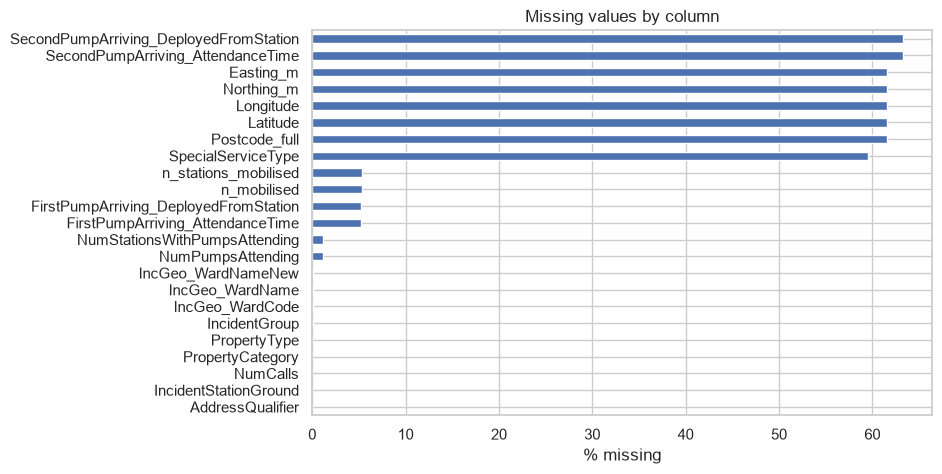

,% missing
SecondPumpArriving_DeployedFromStation,63.2
SecondPumpArriving_AttendanceTime,63.2
Easting_m,61.6
Northing_m,61.6
Longitude,61.6
Latitude,61.6
Postcode_full,61.6
SpecialServiceType,59.5
n_stations_mobilised,5.3
n_mobilised,5.3


In [10]:
missing = (df.isna().mean() * 100).sort_values(ascending=False)
missing = missing[missing > 0]
fig, ax = plt.subplots(figsize=(8, 5))
missing.plot.barh(ax=ax, color="#4C72B0")
ax.set_xlabel("% missing"); ax.set_title("Missing values by column"); ax.invert_yaxis()
savefig("missing_values"); plt.show()
missing.round(1).to_frame("% missing")

In [11]:
# Is missingness related to the incident type? (structural vs random)
pd.crosstab(df["IncidentGroup"], df["FirstPumpArriving_AttendanceTime"].isna(), normalize="index").round(3)

FirstPumpArriving_AttendanceTime,False,True
IncidentGroup,,
False Alarm,0.992,0.008
Fire,0.988,0.012
Special Service,0.885,0.115


**Insights.**
* `Latitude`/`Longitude`/`Easting_m`/`Postcode_full` are missing for ~62% of rows. These are **redacted for
  dwellings** for privacy, so the rounded coordinates (`Easting_rounded`, `Northing_rounded`, complete) are
  used instead.
* `SpecialServiceType` is missing whenever the incident is not a Special Service, so it is missing *by design*.
* `FirstPumpArriving_AttendanceTime` (the basis of the target) is missing for ~5%, mostly Special Service
  incidents where no engine arrived (e.g. cancelled en route). These rows have no label and cannot be used
  for supervised learning.
* `SecondPump…` columns are missing when only one engine attended. They describe events *after* the call,
  so they are excluded anyway (leakage).

### B3. The target: first-engine attendance time

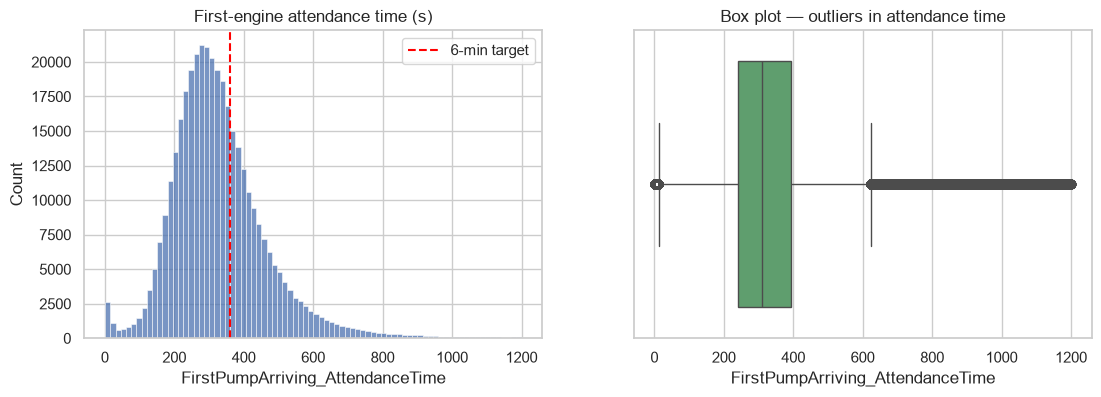

count    377099.0
mean        329.6
std         139.4
min           1.0
1%           31.0
5%          150.0
25%         241.0
50%         310.0
75%         394.0
95%         579.0
99%         803.0
max        1200.0
Name: FirstPumpArriving_AttendanceTime, dtype: float64
Share later than 300s: 53.4%
Share later than 360s: 33.5%
Share later than 480s: 11.5%
Attendance < 30s: 3675 | exactly 1200s (cap?): 7


In [12]:
att = df["FirstPumpArriving_AttendanceTime"]
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(att, bins=80, ax=ax[0], color="#4C72B0")
ax[0].axvline(TARGET_SECONDS, color="red", ls="--", label="6-min target")
ax[0].set_title("First-engine attendance time (s)"); ax[0].legend()
sns.boxplot(x=att, ax=ax[1], color="#55A868")
ax[1].set_title("Box plot — outliers in attendance time")
savefig("target_distribution"); plt.show()

print(att.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).round(1))
for thr in (300, 360, 480):
    print(f"Share later than {thr}s: {(att > thr).sum() / att.notna().sum():.1%}")
print("Attendance < 30s:", (att < 30).sum(), "| exactly 1200s (cap?):", (att == 1200).sum())

**Insights.** The distribution is right-skewed with a median of about 5 minutes. About **one third of incidents
miss the 6-minute target**, so a binary target `late = attendance > 360 s` gives a moderately imbalanced
problem (~1:2). That ratio is workable without resampling, but accuracy alone would be misleading. Very short
times (< 30 s) are implausible for a 999 call → mobilise → drive sequence and are treated as recording errors.
The maximum is exactly 1200 s, which suggests values are **capped at 20 minutes** in the published data.

### B4. Late-arrival rate by call-time factors
Each plot answers a planning question: *when* and *where* is the target missed, and for *which kind* of
property.

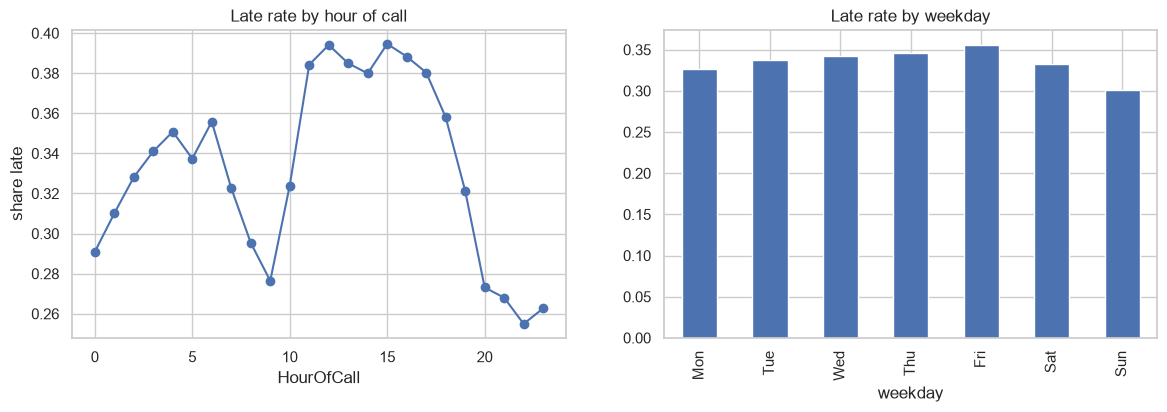

In [13]:
d = df.dropna(subset=["FirstPumpArriving_AttendanceTime"]).copy()
d["late"] = (d["FirstPumpArriving_AttendanceTime"] > TARGET_SECONDS).astype(int)
d["weekday"] = pd.to_datetime(d["DateOfCall"]).dt.day_name().str[:3]

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
d.groupby("HourOfCall")["late"].mean().plot(ax=ax[0], marker="o")
ax[0].set_title("Late rate by hour of call"); ax[0].set_ylabel("share late")
order = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
d.groupby("weekday")["late"].mean().reindex(order).plot.bar(ax=ax[1], color="#4C72B0")
ax[1].set_title("Late rate by weekday")
savefig("late_by_time"); plt.show()

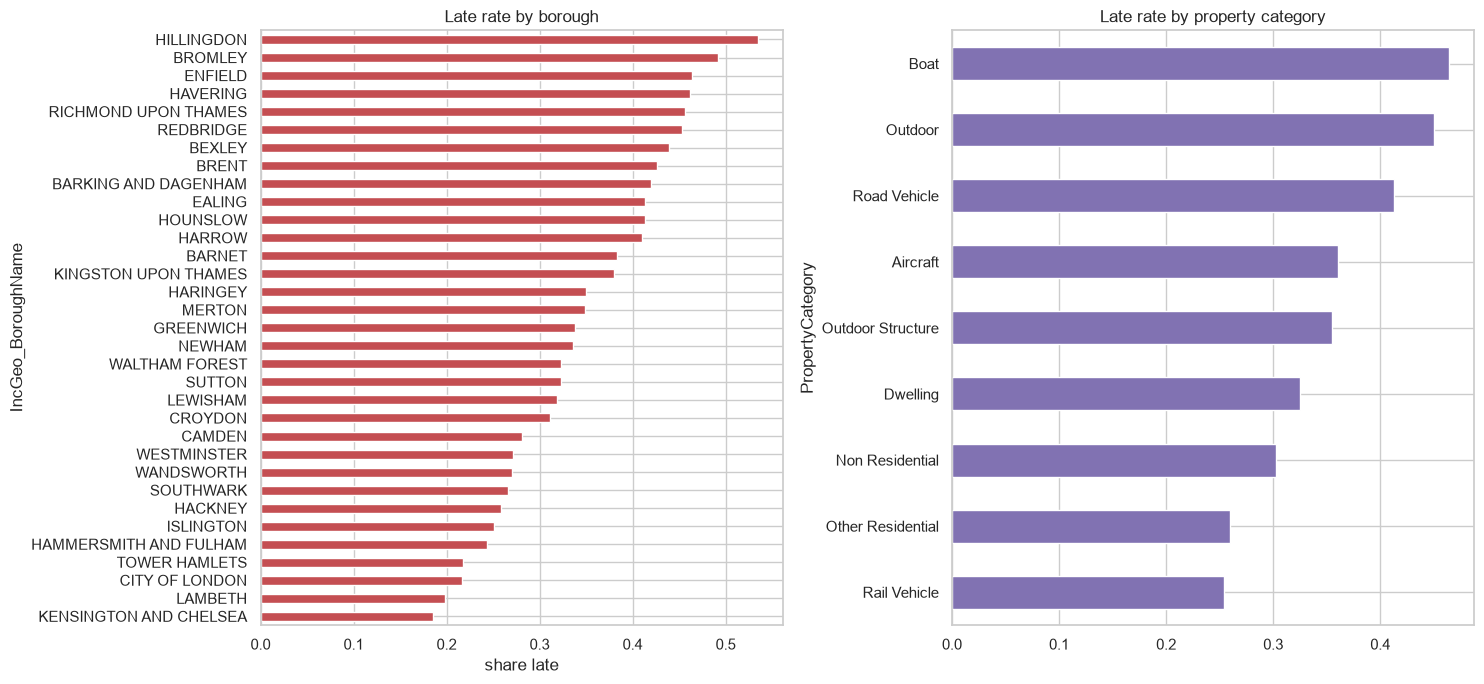

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(15, 7))
d.groupby("IncGeo_BoroughName")["late"].mean().sort_values().plot.barh(ax=ax[0], color="#C44E52")
ax[0].set_title("Late rate by borough"); ax[0].set_xlabel("share late")
d.groupby("PropertyCategory")["late"].mean().sort_values().plot.barh(ax=ax[1], color="#8172B2")
ax[1].set_title("Late rate by property category")
plt.tight_layout(); savefig("late_by_place"); plt.show()

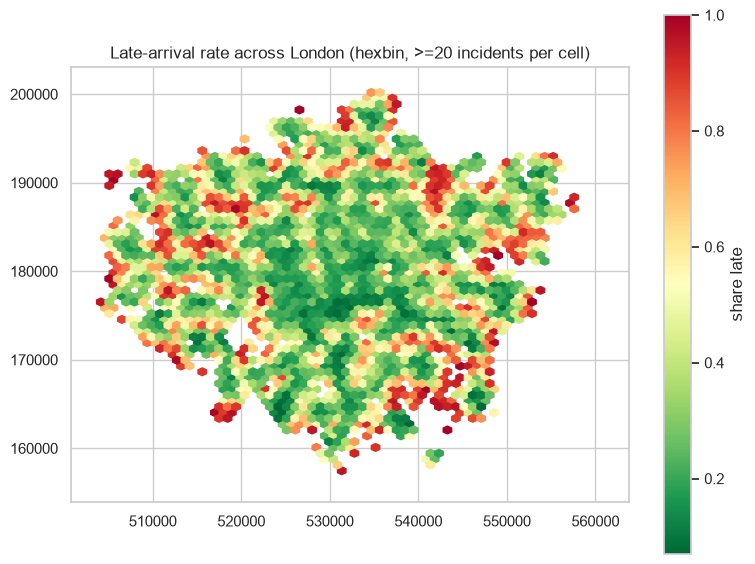

In [15]:
# Spatial view: late rate on a hexagonal grid of rounded easting/northing
fig, ax = plt.subplots(figsize=(9, 7))
hb = ax.hexbin(d["Easting_rounded"], d["Northing_rounded"], C=d["late"], gridsize=60,
               reduce_C_function=np.mean, cmap="RdYlGn_r", mincnt=20)
plt.colorbar(hb, label="share late"); ax.set_aspect("equal")
ax.set_title("Late-arrival rate across London (hexbin, >=20 incidents per cell)")
savefig("late_map"); plt.show()

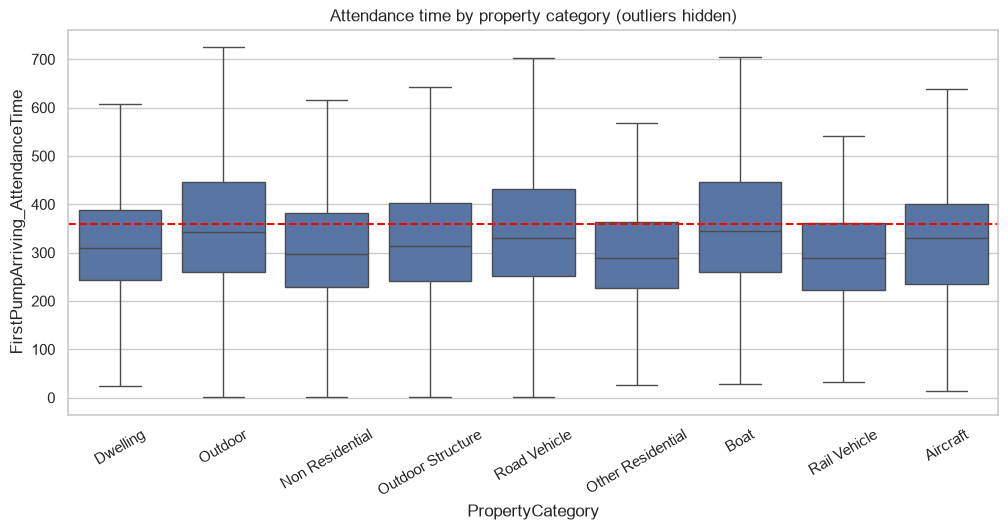

In [16]:
# Distribution of attendance time per property category (box plots show spread and outliers)
fig, ax = plt.subplots(figsize=(12, 5))
sns.boxplot(data=d, x="PropertyCategory", y="FirstPumpArriving_AttendanceTime", ax=ax, showfliers=False)
ax.axhline(TARGET_SECONDS, color="red", ls="--"); ax.tick_params(axis="x", rotation=30)
ax.set_title("Attendance time by property category (outliers hidden)")
savefig("box_property"); plt.show()

**Insights.**
* **Time of day:** the late rate peaks in the afternoon (~39–40% at 12:00–17:00) and is lowest late in the evening
  (~25%), which matches daytime road traffic.
* **Location:** borough is the strongest single signal. Inner boroughs (e.g. Kensington & Chelsea ≈ 18%) rarely
  miss the target, while outer boroughs (e.g. Hillingdon ≈ 53%, Bromley ≈ 49%) often do. The map shows
  late arrivals clustered at the edges of London, where stations are further apart.
* **Property:** outdoor and road-vehicle incidents are late more often (≈41–45%) because they tend to be on
  roads or open land, away from stations, and the address is less precise.

### B5. Correlation matrix
Pearson correlation between numeric variables shows (a) which raw numeric variables relate to attendance
time and (b) redundancy between variables (multicollinearity matters for Logistic Regression).
Engineered features are added to this analysis in Section C.

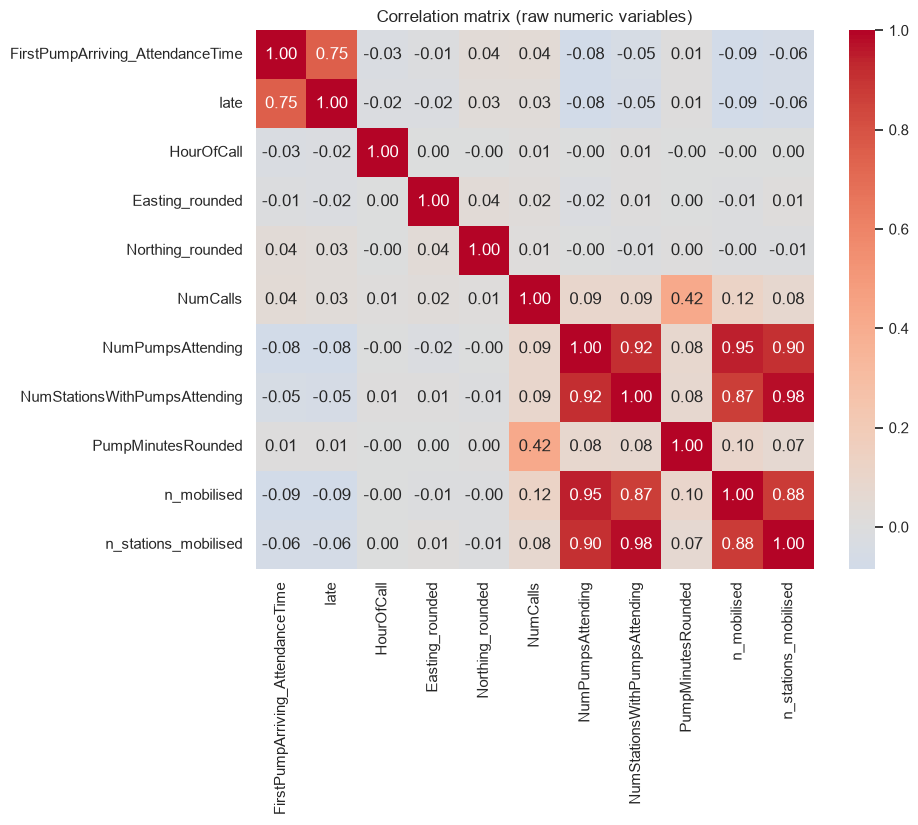

In [17]:
corr_cols = ["FirstPumpArriving_AttendanceTime", "late", "HourOfCall", "Easting_rounded", "Northing_rounded",
             "NumCalls", "NumPumpsAttending", "NumStationsWithPumpsAttending", "PumpMinutesRounded",
             "n_mobilised", "n_stations_mobilised"]
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(d[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation matrix (raw numeric variables)")
savefig("corr_raw"); plt.show()

**Insights.** No single raw numeric variable correlates strongly with attendance time, so a linear model on
raw numbers would be weak. Location and engineered workload/distance features are needed. `NumPumpsAttending`,
`NumStationsWithPumpsAttending`, `n_mobilised` and `PumpMinutesRounded` are strongly inter-correlated: they all
measure the **size of the response**, which is only known *after* the call. They are therefore **leakage** and
are excluded from the model (see C3).

## C. Data Preparation & Feature Engineering

### C1. Cleaning

| Step | Problem | Treatment | Justification |
|---|---|---|---|
| 1 | Rows with no attendance time | Drop | No label exists. Imputing a target would invent the answer. |
| 2 | Attendance < 30 s | Drop | Physically implausible (call → mobilise → drive). Recording error. |
| 3 | Incident times are **UK local time**, mobilisation times are **GMT** | Convert incident call time to UTC | Without this, workload features would be shifted by one hour from April to October (verified below). |
| 4 | Duplicate rows | Check / drop | Duplicates would over-weight some incidents. |
| 5 | Missing categorical values (`PropertyCategory`, ward, …) | Fill with `"Unknown"` | Few rows. Keeps them without inventing a category value. |

In [18]:
prep_steps = [{"step": "Joined incidents (+ aggregated mobilisations)", "rows_removed": 0, "rows_after": len(df)}]
n0 = len(df)
df = df.dropna(subset=["FirstPumpArriving_AttendanceTime"])
print(f"1) dropped {n0 - len(df):,} rows without attendance time")
prep_steps.append({"step": "Drop rows without attendance time (no label)", "rows_removed": n0 - len(df), "rows_after": len(df)})
n1 = len(df)
df = df[df["FirstPumpArriving_AttendanceTime"] >= 30]
print(f"2) dropped {n1 - len(df):,} rows with attendance < 30 s")
prep_steps.append({"step": "Drop implausible attendance < 30 s", "rows_removed": n1 - len(df), "rows_after": len(df)})
n2 = len(df)
print(f"4) duplicate rows: {df.duplicated().sum()}")
df = df.drop_duplicates()
prep_steps.append({"step": "Drop duplicate rows", "rows_removed": n2 - len(df), "rows_after": len(df)})

# 3) Build a proper timestamp and convert UK local time -> UTC (matches mobilisation records)
call_local = pd.to_datetime(df["DateOfCall"].astype(str).str[:10] + " " + df["TimeOfCall"].astype(str))
df["call_utc"] = (call_local.dt.tz_localize("Europe/London", ambiguous="NaT", nonexistent="shift_forward")
                            .dt.tz_convert("UTC").dt.tz_localize(None))
df["call_local"] = call_local
print("rows with ambiguous clock-change time:", df["call_utc"].isna().sum())
n3 = len(df)
df = df.dropna(subset=["call_utc"])
prep_steps.append({"step": "Convert call time UK local -> UTC (drop ambiguous clock-change hour)", "rows_removed": n3 - len(df), "rows_after": len(df)})

# 5) Fill missing categorical values
for c in ["PropertyCategory", "PropertyType", "AddressQualifier", "IncGeo_WardName", "IncidentGroup"]:
    df[c] = df[c].fillna("Unknown")

df["late"] = (df["FirstPumpArriving_AttendanceTime"] > TARGET_SECONDS).astype(int)
df = df.sort_values("call_utc").reset_index(drop=True)
print("Clean shape:", df.shape, "| late rate:", round(df["late"].mean(), 3))

1) dropped 20,804 rows without attendance time
2) dropped 3,675 rows with attendance < 30 s


4) duplicate rows: 0


rows with ambiguous clock-change time: 76


Clean shape: (373348, 44) | late rate: 0.338


In [19]:
# Verify the time-zone correction: the first mobilisation should follow the call within ~1-2 minutes
mob = mobilisations.copy()
mob["mobilised"] = pd.to_datetime(mob["DateAndTimeMobilised"], dayfirst=True, format="mixed")
mob["left"] = pd.to_datetime(mob["DateAndTimeLeft"], dayfirst=True, format="mixed", errors="coerce")
first_mob = mob.groupby("IncidentNumber")["mobilised"].min()
chk = df.set_index("IncidentNumber")[["call_local", "call_utc"]].join(first_mob, how="inner")
chk["month"] = chk["call_local"].dt.month
chk["gap_local_min"] = (chk["mobilised"] - chk["call_local"]).dt.total_seconds() / 60
chk["gap_utc_min"] = (chk["mobilised"] - chk["call_utc"]).dt.total_seconds() / 60
tz_check = chk.groupby("month")[["gap_local_min", "gap_utc_min"]].median().round(2)
tz_check.T

month,1,2,3,4,5,6,7,8,9,10,11,12
gap_local_min,-0.2,-0.2,-0.25,-60.22,-60.23,-60.22,-60.23,-60.23,-60.2,-60.03,0.0,0.0
gap_utc_min,-0.2,-0.2,-0.22,-0.22,-0.23,-0.22,-0.23,-0.23,-0.2,-0.22,0.0,0.0


Before correction the median gap is about **−60 minutes** in the summer months, which is impossible because
an engine cannot be mobilised an hour before the call. After converting to UTC the gap is close to zero
all year round, which confirms the fix.

### C2. Feature engineering
Every feature must be **known at the moment the call is received**.

| Feature | How | Why |
|---|---|---|
| `hour`, `hour_sin`, `hour_cos`, `weekday`, `month`, `is_weekend`, `is_night` | From the local call time | Traffic and staffing vary by time. The sine/cosine encoding tells linear models that 23:00 is next to 00:00. |
| `station_busy` | Engines from the incident's **home station** already out (mobilised before, not yet left) at call time | When the local engine is busy, a more distant station must respond. This is the main operational cause of delay. |
| `ground_calls_60m`, `london_calls_60m` | Incidents in the same station ground / London-wide in the previous 60 min | Short-term demand pressure. |
| `dist_home_station_km`, `dist_nearest_station_km`, `home_is_nearest` | Distance from incident to estimated station locations | Travel distance is the physical driver of attendance time. |
| `PropertyType_grouped` | Types with < 300 training rows grouped as `"Other"` | 282 levels would create many sparse one-hot columns and overfit. |

Station coordinates are not published in the data, so each station's location is **estimated** as the
median coordinates of the 5% fastest incidents it attended **in the training period only** (an engine
arriving in about 1–2 minutes must have been very close to its station). Using training data only prevents
test-set information from leaking into the features.

In [20]:
# --- Time features (local time = what the driver experiences) ---
df["hour"] = df["call_local"].dt.hour
df["weekday"] = df["call_local"].dt.dayofweek          # 0 = Monday
df["month"] = df["call_local"].dt.month
df["is_weekend"] = (df["weekday"] >= 5).astype(int)
df["is_night"] = df["hour"].isin([23, 0, 1, 2, 3, 4, 5, 6]).astype(int)
df["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24)
df["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24)
df["easting_km"] = df["Easting_rounded"] / 1000
df["northing_km"] = df["Northing_rounded"] / 1000

In [21]:
# --- Station workload at call time (from the mobilisation table) ---
# An engine is "busy" from DateAndTimeMobilised until DateAndTimeLeft (left the incident).
mob["left"] = mob["left"].fillna(mob["mobilised"] + pd.Timedelta(minutes=16))   # median duration for 0.05% missing
mob["station"] = mob["DeployedFromStation_Name"].str.strip().str.lower()
df["home_station"] = df["IncidentStationGround"].str.strip().str.lower()

df["station_busy"] = 0
for st, grp in df.groupby("home_station"):
    m = mob[mob["station"] == st]
    starts = np.sort(m["mobilised"].values); ends = np.sort(m["left"].values)
    t = grp["call_utc"].values
    # busy = engines that started before t minus engines that already finished by t
    busy = np.searchsorted(starts, t, side="left") - np.searchsorted(ends, t, side="right")
    df.loc[grp.index, "station_busy"] = busy

# Remove the incident's own engines (mobilised a few seconds before the recorded call time)
own = mob[["IncidentNumber", "station", "mobilised", "left"]].merge(
    df[["IncidentNumber", "home_station", "call_utc"]], on="IncidentNumber")
own = own[(own["station"] == own["home_station"]) & (own["mobilised"] < own["call_utc"]) & (own["left"] > own["call_utc"])]
own_counts = own.groupby("IncidentNumber").size()
df["station_busy"] = (df["station_busy"] - df["IncidentNumber"].map(own_counts).fillna(0)).clip(lower=0).astype(int)
df["station_busy"].value_counts().sort_index().head(6)

station_busy
0    332713
1     34779
2      5497
3       212
4        72
5        26
Name: count, dtype: int64

In [22]:
# --- Recent demand: incidents in the previous 60 minutes (London-wide and in the same station ground) ---
t_all = df["call_utc"].values
window = np.timedelta64(60, "m")
df["london_calls_60m"] = np.searchsorted(t_all, t_all, side="left") - np.searchsorted(t_all, t_all - window, side="left")
df["ground_calls_60m"] = 0
for st, grp in df.groupby("home_station"):
    t = grp["call_utc"].values   # already sorted because df is sorted by call_utc
    df.loc[grp.index, "ground_calls_60m"] = (np.searchsorted(t, t, side="left")
                                             - np.searchsorted(t, t - window, side="left"))
df[["london_calls_60m", "ground_calls_60m"]].describe().round(2)

,london_calls_60m,ground_calls_60m
count,373348.00,373348.00
mean,17.23,0.22
std,7.28,0.50
min,0.00,0.00
25%,12.00,0.00
50%,17.00,0.00
75%,21.00,0.00
max,130.00,16.00


### C3. Time-based train / test split
The model will be used on **future** calls, so it is evaluated the same way: it is trained on **2024–2025**
and tested on **2026** (Jan–Oct), which the model never sees. A random split would let the model learn from
incidents that happen *after* the ones it is tested on (look-ahead bias) and would overstate performance.
Hyperparameters are tuned with `TimeSeriesSplit` cross-validation inside the training period, and the
decision threshold is chosen on a **validation set** (the last 3 months of 2025) that is separate from
the test set.

In [23]:
train_mask = df["call_local"] < "2026-01-01"
valid_mask = (df["call_local"] >= "2025-10-01") & train_mask
print(f"train: {train_mask.sum():,}  (of which validation tail: {valid_mask.sum():,})   test: {(~train_mask).sum():,}")
print("late rate train / test:", df.loc[train_mask, 'late'].mean().round(3), "/", df.loc[~train_mask, 'late'].mean().round(3))

train: 255,555  (of which validation tail: 32,912)   test: 117,793
late rate train / test: 0.327 / 0.363


In [24]:
# --- Distance features: station locations estimated from TRAINING data only ---
tr = df[train_mask]
fast = tr[tr["FirstPumpArriving_AttendanceTime"] <= tr.groupby("FirstPumpArriving_DeployedFromStation")
          ["FirstPumpArriving_AttendanceTime"].transform(lambda s: s.quantile(0.05))]
stations = (fast.assign(st=fast["FirstPumpArriving_DeployedFromStation"].str.strip().str.lower())
                .groupby("st")[["easting_km", "northing_km"]].median())
print("estimated station locations:", len(stations))

S = stations.values
P = df[["easting_km", "northing_km"]].values
D = np.sqrt(((P[:, None, :] - S[None, :, :]) ** 2).sum(axis=2))     # incidents x stations distance matrix (km)
df["dist_nearest_station_km"] = D.min(axis=1)
idx = {s: i for i, s in enumerate(stations.index)}
home_i = df["home_station"].map(idx)
df["dist_home_station_km"] = np.where(home_i.notna(), D[np.arange(len(df)), home_i.fillna(0).astype(int)], np.nan)
df["dist_home_station_km"] = df["dist_home_station_km"].fillna(df["dist_nearest_station_km"])
df["home_is_nearest"] = (stations.index.values[D.argmin(axis=1)] == df["home_station"].values).astype(int)
del D
df[["dist_nearest_station_km", "dist_home_station_km", "home_is_nearest"]].describe().round(2)

estimated station locations: 103


,dist_nearest_station_km,dist_home_station_km,home_is_nearest
count,373348.00,373348.00,373348.00
mean,1.29,1.33,0.88
std,0.71,0.76,0.32
min,0.00,0.00,0.00
25%,0.76,0.76,1.00
50%,1.20,1.22,1.00
75%,1.71,1.77,1.00
max,7.59,8.42,1.00


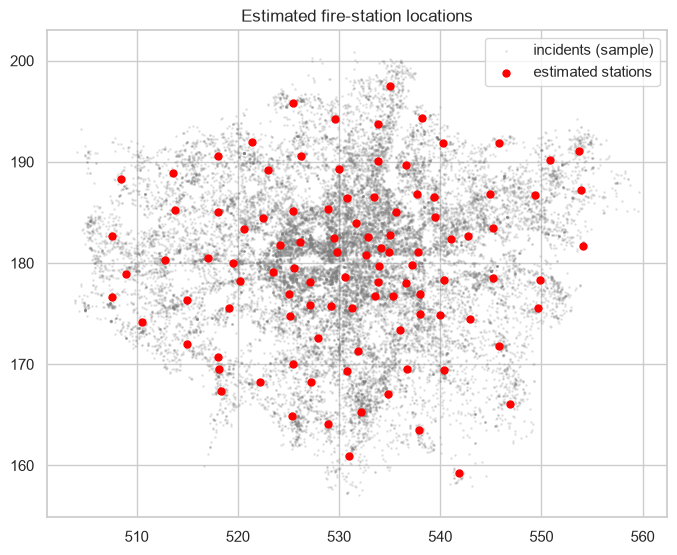

In [25]:
# Plot the estimated station locations over the incident cloud (sanity check)
fig, ax = plt.subplots(figsize=(8, 7))
ax.scatter(df["easting_km"].sample(30000, random_state=1), df["northing_km"].sample(30000, random_state=1),
           s=1, alpha=0.15, color="grey", label="incidents (sample)")
ax.scatter(stations["easting_km"], stations["northing_km"], s=25, color="red", label="estimated stations")
ax.set_aspect("equal"); ax.legend(); ax.set_title("Estimated fire-station locations")
savefig("stations"); plt.show()

In [26]:
# --- Rare-category grouping for PropertyType (levels learned on training data only) ---
pt_counts = df.loc[train_mask, "PropertyType"].value_counts()
keep_types = pt_counts[pt_counts >= 300].index
df["PropertyType_grouped"] = df["PropertyType"].where(df["PropertyType"].isin(keep_types), "Other")
print(f"PropertyType: {df['PropertyType'].nunique()} levels -> {df['PropertyType_grouped'].nunique()}")

PropertyType: 283 levels -> 74


### C4. Final feature set and excluded (leakage) columns

| Excluded column(s) | Reason |
|---|---|
| `SecondPump…`, `NumPumpsAttending`, `NumStationsWithPumpsAttending`, `PumpCount`, `PumpMinutesRounded`, `Notional Cost`, `n_mobilised`, `n_stations_mobilised` | Size/duration of the response, only known **after** the call |
| `FirstPumpArriving_DeployedFromStation` | Which station *actually* arrived first is decided during the response |
| `IncidentGroup`, `StopCodeDescription`, `SpecialServiceType` | Recorded **after** attendance (e.g. "false alarm" is confirmed on arrival) |
| `NumCalls` | Calls keep arriving while waiting, so late incidents collect more calls (reverse causation) |
| `UPRN`, `USRN`, postcodes, exact lat/long | Identifiers, or redacted for dwellings (privacy). Rounded coordinates are used instead. |
| `IncGeo_WardName` (~690 levels) | Too granular. Location is captured by coordinates, borough and station ground. |

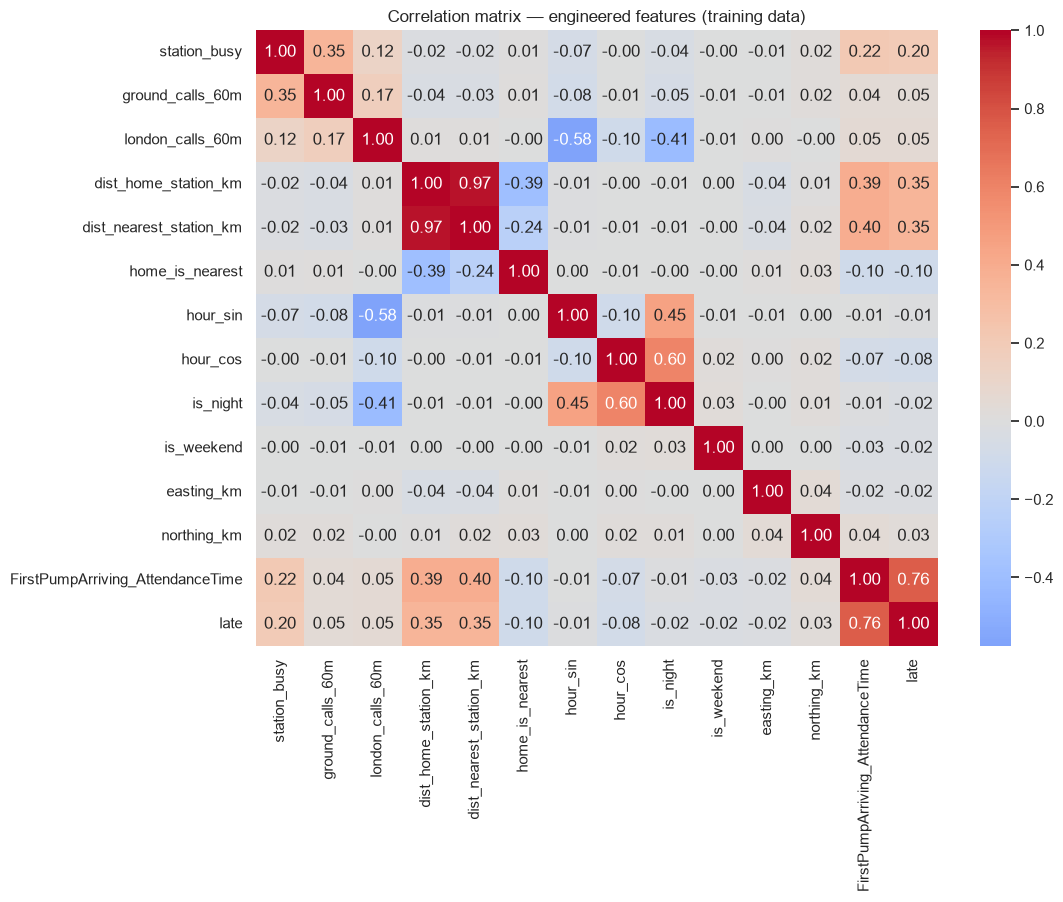

In [27]:
# Correlation of engineered numeric features with the target (point-biserial = Pearson with a 0/1 variable)
eng = ["station_busy", "ground_calls_60m", "london_calls_60m", "dist_home_station_km",
       "dist_nearest_station_km", "home_is_nearest", "hour_sin", "hour_cos", "is_night", "is_weekend",
       "easting_km", "northing_km", "FirstPumpArriving_AttendanceTime", "late"]
fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(df.loc[train_mask, eng].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation matrix — engineered features (training data)")
savefig("corr_engineered"); plt.show()

In [28]:
CAT = ["IncGeo_BoroughName", "IncidentStationGround", "PropertyCategory", "PropertyType_grouped", "AddressQualifier"]
NUM = ["hour_sin", "hour_cos", "weekday", "month", "is_weekend", "is_night", "easting_km", "northing_km",
       "station_busy", "ground_calls_60m", "london_calls_60m",
       "dist_home_station_km", "dist_nearest_station_km", "home_is_nearest"]
FEATURES = CAT + NUM

X_train, y_train = df.loc[train_mask, FEATURES], df.loc[train_mask, "late"]
X_test, y_test = df.loc[~train_mask, FEATURES], df.loc[~train_mask, "late"]
fit_mask = train_mask & ~valid_mask       # used for fitting before threshold selection
X_fit, y_fit = df.loc[fit_mask, FEATURES], df.loc[fit_mask, "late"]
X_val, y_val = df.loc[valid_mask, FEATURES], df.loc[valid_mask, "late"]
print(X_train.shape, X_test.shape)

# Preprocessing: one-hot for categoricals (unseen test categories are ignored), scaling for numerics
preprocess = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=50), CAT),
    ("num", StandardScaler(), NUM)])

(255555, 19) (117793, 19)


**Why scaling?** Logistic Regression uses an L2 penalty, which is only fair across features when they are on
the same scale (otherwise a feature measured in km is penalised differently from one measured in counts).
Tree models do not need scaling, but using the same preprocessing for all models keeps the comparison fair
and simple.

## D. Model Training

Three supervised classifiers with different assumptions are compared against a trivial baseline:

| Model | How it works / assumptions | Why it fits this problem |
|---|---|---|
| **Logistic Regression** | Linear in the log-odds. Assumes additive, independent effects. | Interpretable baseline. Shows how much is explained by simple additive effects. |
| **Random Forest** | Bagged decision trees on bootstrap samples with random feature subsets. Few assumptions; models interactions. | Captures non-linear effects (e.g. distance matters more at rush hour). Robust to outliers. |
| **LightGBM** (gradient boosting) | Trees added one after another, each correcting the previous errors. Leaf-wise growth. | Usually the strongest on tabular data. Fast on 300k+ rows. |

**Tuning.** `RandomizedSearchCV` with `TimeSeriesSplit(n_splits=3)`, so each validation fold is later than
its training fold. The scoring metric is **ROC-AUC**, which measures ranking quality independent of the
threshold. Random search is used instead of grid search because it covers wide ranges with a fixed budget.
To keep run time reasonable, tuning uses a chronologically ordered sample of 120,000 training rows. The
final models are then refitted on the full fitting set.

In [29]:
tscv = TimeSeriesSplit(n_splits=3)
tune_idx = np.sort(np.random.RandomState(RANDOM_STATE).choice(len(X_fit), size=min(120_000, len(X_fit)), replace=False))
X_tune, y_tune = X_fit.iloc[tune_idx], y_fit.iloc[tune_idx]

def tune(model, params, n_iter):
    pipe = Pipeline([("prep", preprocess), ("model", model)])
    search = RandomizedSearchCV(pipe, params, n_iter=n_iter, scoring="roc_auc", cv=tscv,
                                random_state=RANDOM_STATE, n_jobs=-1, verbose=0)
    t = time.time(); search.fit(X_tune, y_tune)
    print(f"{type(model).__name__}: best CV ROC-AUC = {search.best_score_:.4f}  ({time.time() - t:.0f}s)")
    print("  best params:", search.best_params_)
    return search

searches = {}

In [30]:
# Logistic Regression
# C = inverse regularisation strength; class_weight='balanced' re-weights the minority (late) class
searches["Logistic Regression"] = tune(
    LogisticRegression(max_iter=2000, solver="lbfgs"),
    {"model__C": loguniform(1e-3, 10), "model__class_weight": [None, "balanced"]}, n_iter=10)

LogisticRegression: best CV ROC-AUC = 0.7655  (12s)
  best params: {'model__C': np.float64(0.02161894240657444), 'model__class_weight': 'balanced'}


In [31]:
# Random Forest
# n_estimators = number of trees, max_depth/min_samples_leaf limit tree size (overfitting),
# max_features = share of features tried at each split (decorrelates trees)
searches["Random Forest"] = tune(
    RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    {"model__n_estimators": randint(100, 250), "model__max_depth": randint(8, 22),
     "model__min_samples_leaf": randint(5, 50), "model__max_features": ["sqrt", 0.3],
     "model__class_weight": [None, "balanced_subsample"]}, n_iter=8)

RandomForestClassifier: best CV ROC-AUC = 0.7715  (222s)
  best params: {'model__class_weight': 'balanced_subsample', 'model__max_depth': 20, 'model__max_features': 0.3, 'model__min_samples_leaf': 29, 'model__n_estimators': 148}


In [32]:
# LightGBM
# num_leaves = tree complexity, learning_rate = step size, n_estimators = boosting rounds,
# min_child_samples = minimum rows per leaf, subsample/colsample_bytree = row/feature sampling (regularisation)
searches["LightGBM"] = tune(
    LGBMClassifier(random_state=RANDOM_STATE, verbose=-1, n_jobs=-1),
    {"model__n_estimators": randint(200, 800), "model__learning_rate": loguniform(0.02, 0.2),
     "model__num_leaves": randint(15, 127), "model__min_child_samples": randint(20, 200),
     "model__subsample": uniform(0.6, 0.4), "model__subsample_freq": [1],
     "model__colsample_bytree": uniform(0.5, 0.5), "model__reg_lambda": loguniform(1e-3, 10)}, n_iter=15)

LGBMClassifier: best CV ROC-AUC = 0.7815  (291s)
  best params: {'model__colsample_bytree': np.float64(0.7956488938538635), 'model__learning_rate': np.float64(0.03764885638233941), 'model__min_child_samples': 54, 'model__n_estimators': 661, 'model__num_leaves': 17, 'model__reg_lambda': np.float64(1.1044350847124695), 'model__subsample': np.float64(0.8245108790277985), 'model__subsample_freq': 1}


In [33]:
# Refit each tuned pipeline on the full fitting period (2024 - Sep 2025)
models = {"Baseline (majority)": Pipeline([("prep", preprocess), ("model", DummyClassifier(strategy="prior"))])}
for name, s in searches.items():
    models[name] = s.best_estimator_
for name, m in models.items():
    t = time.time(); m.fit(X_fit, y_fit); print(f"fitted {name} in {time.time() - t:.0f}s")

fitted Baseline (majority) in 2s


fitted Logistic Regression in 2s


fitted Random Forest in 167s


fitted LightGBM in 4s


### Decision threshold
Each model outputs a probability. The default cut-off of 0.5 is not necessarily right with a 1:2 class
ratio. For each model the threshold that **maximises F1 on the validation set** (Oct–Dec 2025) is chosen,
which balances finding late incidents (recall) against false alerts (precision). The test set is not used
for this choice.

In [34]:
thresholds = {}
for name, m in models.items():
    if name.startswith("Baseline"):
        thresholds[name] = 0.5; continue
    p = m.predict_proba(X_val)[:, 1]
    prec, rec, thr = precision_recall_curve(y_val, p)
    f1 = 2 * prec * rec / (prec + rec + 1e-12)
    thresholds[name] = float(thr[np.argmax(f1[:-1])])
    print(f"{name}: threshold = {thresholds[name]:.3f}  (validation F1 = {f1[:-1].max():.3f})")

Logistic Regression: threshold = 0.465  (validation F1 = 0.618)


Random Forest: threshold = 0.471  (validation F1 = 0.628)

LightGBM: threshold = 0.309  (validation F1 = 0.632)


## E. Model Evaluation (held-out 2026 test set)

| Metric | Meaning here | Why it is used |
|---|---|---|
| **ROC-AUC** | Probability that a random late incident is ranked above a random on-time one | Threshold-free ranking quality. Main tuning metric. |
| **PR-AUC** (average precision) | Precision–recall trade-off for the late class | More informative than ROC-AUC when the positive class is the minority. |
| **Recall / TPR** | Share of late incidents that are flagged | Missing a late incident is the costly error for planning. |
| **TNR (specificity)** | Share of on-time incidents correctly not flagged | Too many false alerts waste resources. |
| **Precision** | Share of flagged incidents that really were late | Trust in alerts. |
| **F1** | Harmonic mean of precision and recall | Single balanced figure at the chosen threshold. |
| Accuracy | Share correct | Reported for completeness only. A model that predicts "on time" for everything already gets ~65%. |

In [35]:
rows, probs = [], {}
for name, m in models.items():
    p = m.predict_proba(X_test)[:, 1]; probs[name] = p
    yhat = (p >= thresholds[name]).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, yhat).ravel()
    rows.append({"Model": name,
                 "ROC-AUC": roc_auc_score(y_test, p), "PR-AUC": average_precision_score(y_test, p),
                 "Recall (TPR)": tp / (tp + fn), "TNR": tn / (tn + fp),
                 "Precision": precision_score(y_test, yhat, zero_division=0),
                 "F1": f1_score(y_test, yhat), "Accuracy": accuracy_score(y_test, yhat),
                 "Threshold": thresholds[name]})
results = pd.DataFrame(rows).set_index("Model").round(3)
results

,ROC-AUC,PR-AUC,Recall (TPR),TNR,Precision,F1,Accuracy,Threshold
Model,,,,,,,,
Baseline (majority),0.500,0.363,0.000,1.000,0.000,0.000,0.637,0.500
Logistic Regression,0.771,0.656,0.731,0.675,0.561,0.635,0.695,0.465
Random Forest,0.784,0.690,0.705,0.723,0.592,0.644,0.717,0.471
LightGBM,0.791,0.697,0.721,0.715,0.590,0.649,0.717,0.309


**Interpretation of the results table.**
* All three models clearly beat the baseline. The baseline has ROC-AUC 0.5 and PR-AUC 0.363, which equals
  the late rate in 2026.
* **LightGBM is best on every ranking metric**: ROC-AUC 0.791, PR-AUC 0.697, F1 0.649. Random Forest is
  close behind (0.784 / 0.690). Logistic Regression is clearly weaker (0.771 / 0.656). The gap between the
  linear and the tree models shows that **non-linear effects and interactions** matter (for example, distance
  matters more when the local station is busy), but most of the signal is already captured additively.
* At its chosen threshold, LightGBM flags **72% of late incidents** (recall) with precision 0.59, so about
  6 in 10 alerts are real. It correctly leaves 72% of on-time incidents unflagged (TNR).
* Accuracy (0.717) is only 8 points above always predicting "on time" (0.637), which is why accuracy is not
  used to choose between models.
* Cross-validated ROC-AUC during tuning (0.78) is close to the test score (0.79), so there is **no sign of
  overfitting**. The test period has a higher late rate than training (36.3% vs 32.7%), a mild shift in
  conditions that the model coped with.
* **Ceiling:** ROC-AUC ≈ 0.79 means a fair amount of delay is not predictable from call-time information.
  Live traffic, road closures and the exact position of engines on the road are not in the data.

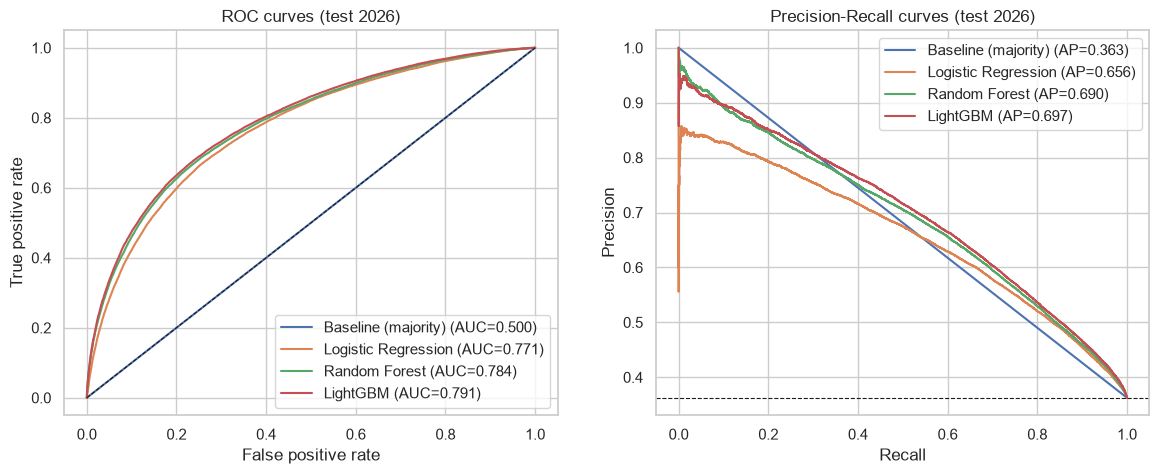

In [36]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for name, p in probs.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    ax[0].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, p):.3f})")
    pr, rc, _ = precision_recall_curve(y_test, p)
    ax[1].plot(rc, pr, label=f"{name} (AP={average_precision_score(y_test, p):.3f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=0.8); ax[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curves (test 2026)")
ax[1].axhline(y_test.mean(), color="k", ls="--", lw=0.8); ax[1].set(xlabel="Recall", ylabel="Precision", title="Precision-Recall curves (test 2026)")
ax[0].legend(); ax[1].legend()
savefig("roc_pr"); plt.show()

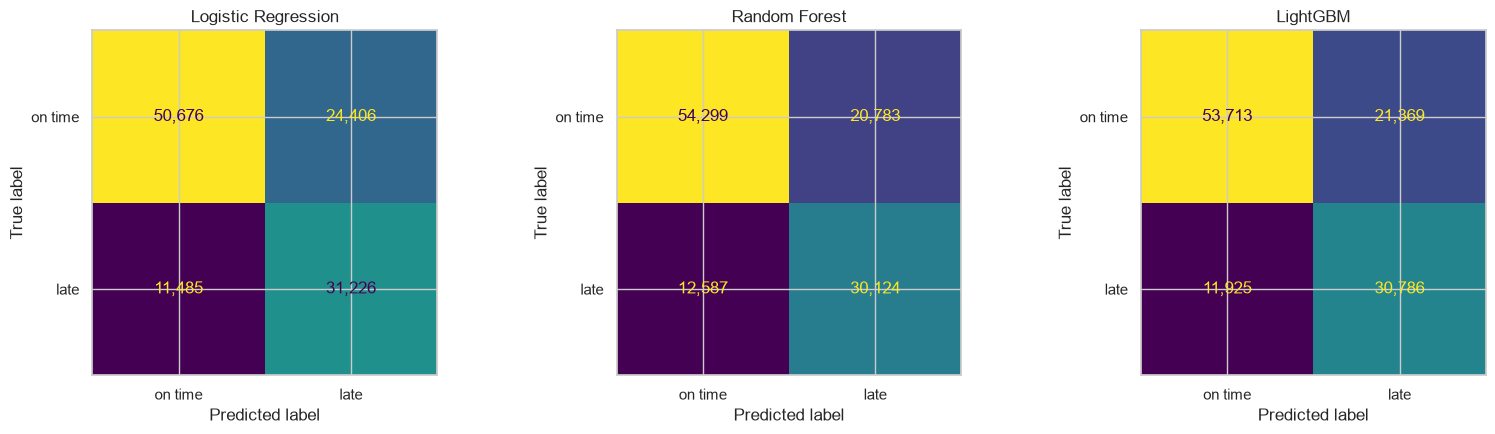

In [37]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, name in zip(axes, [n for n in models if not n.startswith("Baseline")]):
    yhat = (probs[name] >= thresholds[name]).astype(int)
    ConfusionMatrixDisplay(confusion_matrix(y_test, yhat), display_labels=["on time", "late"]).plot(ax=ax, colorbar=False, values_format=",")
    ax.set_title(name)
plt.tight_layout(); savefig("confusion_matrices"); plt.show()

### Final model selection and interpretation
The final model is the one with the highest **PR-AUC**, because the planning use case is about finding the
late (minority) incidents. Differences below 0.005 PR-AUC are within run-to-run noise, so such models are
treated as tied and the tie is broken by **ROC-AUC**. Practical factors (training time, model size, speed in
the deployed app) are also discussed in the report. Permutation
importance on the test set then shows which inputs the model relies on. It measures how much ROC-AUC drops
when a feature is randomly shuffled, which makes it comparable across feature types.

Models tied on PR-AUC (within 0.005): ['LightGBM']
Final model: LightGBM


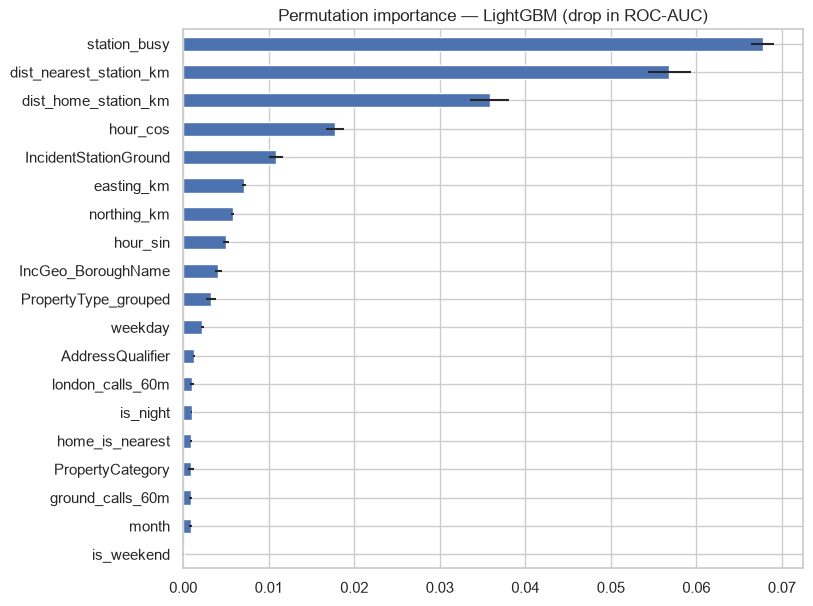

In [38]:
# Rule: highest PR-AUC; models within 0.005 PR-AUC are treated as tied and the tie is broken by ROC-AUC
cand = results.drop(index="Baseline (majority)")
tied = cand[cand["PR-AUC"] >= cand["PR-AUC"].max() - 0.005]
final_name = tied["ROC-AUC"].idxmax()
print("Models tied on PR-AUC (within 0.005):", list(tied.index))
final_model = models[final_name]
print("Final model:", final_name)

sample = X_test.sample(min(20000, len(X_test)), random_state=RANDOM_STATE)
pi = permutation_importance(final_model, sample, y_test.loc[sample.index], scoring="roc_auc",
                            n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
importance = pd.Series(pi.importances_mean, index=FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(8, 7))
importance.plot.barh(ax=ax, color="#4C72B0", xerr=pd.Series(pi.importances_std, index=FEATURES)[importance.index])
ax.set_title(f"Permutation importance — {final_name} (drop in ROC-AUC)")
savefig("permutation_importance"); plt.show()

**Interpretation of feature importance.** The three most important inputs are all engineered features:
**`station_busy`** (ROC-AUC drops by ~0.068 when it is shuffled), **distance to the nearest station** (~0.057)
and **distance to the home station** (~0.036), followed by time of day (`hour_cos`). The target is missed
mainly when **the local engine is already out** or the incident is **far from any station**, which matches
how fire services operate. Once location and distance are known, borough and property type add little.

**Planning implications:** (1) moving engines to cover a station whose engines are out could reduce late
arrivals, and (2) the outer boroughs with long distances between stations (Hillingdon, Bromley, Enfield,
Havering) are where station coverage limits performance.

In [39]:
# Error analysis: is performance consistent across boroughs? (fairness / reliability check)
test_df = df.loc[~train_mask, ["IncGeo_BoroughName", "late"]].copy()
test_df["p"] = probs[final_name]
by_b = test_df.groupby("IncGeo_BoroughName").apply(
    lambda g: pd.Series({"n": len(g), "late_rate": g["late"].mean(), "mean_pred": g["p"].mean(),
                         "auc": roc_auc_score(g["late"], g["p"]) if g["late"].nunique() > 1 else np.nan}))
by_b.sort_values("auc").round(3).head(10)

,n,late_rate,mean_pred,auc
IncGeo_BoroughName,,,,
ISLINGTON,3920.0,0.266,0.248,0.695
HACKNEY,4520.0,0.281,0.261,0.706
CITY OF LONDON,792.0,0.210,0.215,0.725
KENSINGTON AND CHELSEA,3780.0,0.209,0.182,0.732
CAMDEN,4765.0,0.292,0.281,0.735
WESTMINSTER,7166.0,0.280,0.273,0.744
MERTON,1909.0,0.379,0.351,0.746
TOWER HAMLETS,4903.0,0.238,0.225,0.748
WALTHAM FOREST,3437.0,0.354,0.328,0.753


**Error analysis.** The model ranks incidents least well in dense **inner boroughs** (Islington AUC ≈ 0.70,
Hackney ≈ 0.71). There, stations are close together, the late rate is low, and delays depend on things the
data does not record (congestion, access to the building). In every borough the mean predicted probability
is close to the observed late rate, but slightly lower. This mild **under-prediction** also shows in the
calibration plot below and is consistent with 2026 being a "later" year than the training years. For a
deployed tool this suggests periodic retraining and monitoring by area.

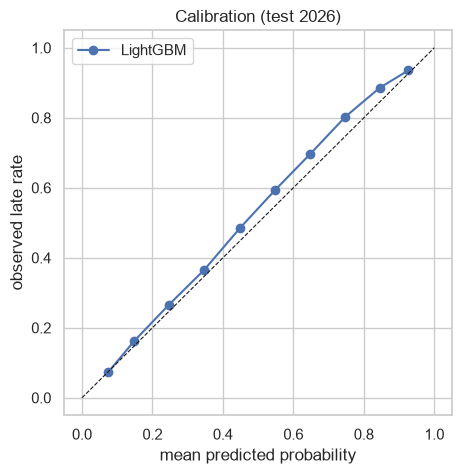

In [40]:
# Calibration: do predicted probabilities match observed late rates?
from sklearn.calibration import calibration_curve
frac, mean_p = calibration_curve(y_test, probs[final_name], n_bins=10)
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot(mean_p, frac, marker="o", label=final_name); ax.plot([0, 1], [0, 1], "k--", lw=0.8)
ax.set(xlabel="mean predicted probability", ylabel="observed late rate", title="Calibration (test 2026)"); ax.legend()
savefig("calibration"); plt.show()

## F. Save artefacts for the Streamlit app
The app reuses exactly what the notebook produced: the fitted pipeline (preprocessing + model), the
threshold, test metrics and curves, and a compact cleaned dataset for the dashboard.

In [41]:
joblib.dump({"model": final_model, "model_name": final_name, "threshold": thresholds[final_name],
             "features": FEATURES, "cat": CAT, "num": NUM}, MODELS / "final_model.joblib", compress=3)

curves = {}
for name, p in probs.items():
    fpr, tpr, _ = roc_curve(y_test, p); pr, rc, _ = precision_recall_curve(y_test, p)
    step_r, step_p = max(1, len(fpr) // 400), max(1, len(pr) // 400)
    curves[name] = {"fpr": fpr[::step_r].tolist(), "tpr": tpr[::step_r].tolist(),
                    "precision": pr[::step_p].tolist(), "recall": rc[::step_p].tolist(),
                    "cm": confusion_matrix(y_test, (p >= thresholds[name]).astype(int)).tolist()}
json.dump({"results": results.reset_index().to_dict(orient="records"), "curves": curves,
           "final_model": final_name, "importance": importance.sort_values(ascending=False).to_dict(),
           "station_locations": stations.reset_index().to_dict(orient="records"),
           "test_rows": int(len(X_test)), "train_rows": int(len(X_train)),
           "prep_log": {"steps": prep_steps, "tz_check": tz_check.reset_index().to_dict(orient="records")}},
          open(MODELS / "evaluation.json", "w"), indent=1)

app_cols = ["IncidentNumber", "call_local", "CalYear", "hour", "weekday", "month", "IncidentGroup",
            "PropertyCategory", "PropertyType", "PropertyType_grouped", "AddressQualifier", "IncGeo_BoroughName",
            "IncidentStationGround", "Easting_rounded", "Northing_rounded", "easting_km", "northing_km",
            "FirstPumpArriving_AttendanceTime", "late", "station_busy", "ground_calls_60m", "london_calls_60m",
            "dist_home_station_km", "dist_nearest_station_km", "home_is_nearest", "is_weekend", "is_night",
            "hour_sin", "hour_cos"]
out = df[app_cols].copy()
for c in out.select_dtypes(["object", "string"]).columns:
    out[c] = out[c].astype("category")
out.to_parquet(PROCESSED / "incidents_clean.parquet", index=False, compression="zstd")
print("saved:", [p.name for p in MODELS.iterdir()], (PROCESSED / "incidents_clean.parquet").stat().st_size / 1e6, "MB")

saved: ['evaluation.json', 'final_model.joblib'] 9.986679 MB


## Summary
* Joined incident and mobilisation records (2024 – Oct 2026), corrected a one-hour time-zone mismatch between
  them, removed unlabeled and implausible records, and engineered call-time features: time of day, station
  workload, recent demand and distance to estimated station locations.
* Trained and tuned Logistic Regression, Random Forest and LightGBM with time-ordered cross-validation, and
  evaluated them on unseen 2026 data.
* See the results table, curves and importance plot above. The findings, limitations and ethics are
  discussed in the written report.